# Single Populations

<!-- * Single populations
  * Are there *any* single populations? 
  * Exponential growth
    * Metabolic basis
  * From populations to alleles
    * Basic pop gen
  * Logistic growth
    * Density dependence
    * Logistic growth as an "effective" model
      * SIS model (VJ)
    * Bifurcations (+Intro to theory - VJ) 
  * Evolutionary dynamics
  * Stochasticity
  * Applications/Examples
  * Stage and age structured populations
    * Stage- vs Age-structured models
    * IPMs
  * Applications/Examples -->

In the [**Metabolic basis of life** chapter](metabolic-basis) we focused on how organisms acquire and transform energy and materials, and how *temperature* and *body/cell size* shape the pace of those processes. In microbes in particular, metabolism sets the tempo of **cell division**: faster energy flux generally supports faster biomass production and shorter doubling times.

This chapter builds directly on that foundation, but shifts the scale of description from *individuals* to **populations**. Population models are, at their core, bookkeeping: they track how births, deaths, and resource limitation change the number of individuals through time. The key idea is that many mechanistic details (enzyme kinetics, ATP production, maintenance costs) can be compressed into a small number of *rates*—and those rates are precisely what metabolism helps us understand and predict.

By the end of this chapter you should be able to:
- Move between **discrete-time** (difference equation) and **continuous-time** (differential equation) descriptions of growth, and know when each is appropriate.
- Interpret exponential growth as a consequence of an approximately constant **per-capita** growth rate, and connect that rate to **doubling time** and (conceptually) to metabolic constraints.
- Add simple, biologically motivated modifiers—especially **temperature dependence**—to growth models (building on the metabolic arguments from the previous chapter).
- Understand why unbounded exponential growth is rarely sustainable, motivating **density dependence** and the **logistic** model as an effective description of limited resources.

As we go, we’ll keep using microbes as a running example for the same reasons as in the previous chapter: they make the discrete nature of reproduction (cell division) obvious, they connect cleanly to metabolic ideas, and they let us test models quickly with simple simulations and data.

```{admonition} Notation (quick glossary)
:class: tip

| Symbol | Meaning | Typical units |
|---|---|---|
| $N_t$ | abundance at discrete step $t$ | individuals |
| $N(t)$ | abundance at continuous time $t$ | individuals |
| $R$ | discrete multiplicative growth factor per step | dimensionless |
| $r$ | intrinsic per-capita growth rate ("Malthusian" parameter) | time$^{-1}$ |
| $\mu$ | alternate notation for intrinsic per-capita growth rate (common in microbiology) | time$^{-1}$ |
| $t_d$ | doubling time ($t_d=\ln 2 / r$) | time |
| $K$ | carrying capacity (here: abundance unless stated) | individuals |
| $x_t$ | scaled abundance (often $x_t=N_t/K$) | dimensionless |
| $r_{\mathrm{map}}$ | logistic-map parameter | dimensionless |
| $\mathbf{u}_t$ | structured population vector (age/stage abundances) | individuals |
| $L$ | Leslie (projection) matrix | dimensionless |
| $\lambda_1$ | dominant eigenvalue of $L$ (asymptotic growth factor per step) | dimensionless |
| $p(t)$ | fraction of occupied patches (metapopulation) | dimensionless |
| $c,e$ | colonisation and extinction rates | time$^{-1}$ |

We use **$r$** throughout for the intrinsic per-capita growth rate. You will also see **$\mu$** in the literature (especially for microbial growth rates); in this chapter you can treat them as the same parameter ($\mu \equiv r$) unless we explicitly note otherwise.
```

## Discrete (Geometric) Growth

Consider a microbial population that reproduces synchronously once per time step (e.g., once every 1 hour, or 1 day, etc.).

### Basic Model

If $N_t$ denotes the population size at discrete time step $t$, then a simple discrete growth model is:

$$ N_{t+1} = R\,N_t. $$

Here:
- $R$ is the **discrete multiplicative growth factor per time step** ($R>1$ for growth, $0<R<1$ for decay).
- Over $T$ steps, $N_T = R^T\,N_0$.

**Units sanity check**
- $R$ is **dimensionless** (a multiplier “per step”).
- If one step corresponds to $\Delta t$ units of time, then the continuous-time rate relates as $R = e^{r\,\Delta t}$ (see below).

### Example: Synchronous Cell Division
Each microbial cell divides into two after a fixed time step. Then $R=2$. So,

$$ N_{t+1} = 2 N_t. $$

In practice, real cells do not all divide at the exact same moment—division is somewhat stochastic. But if we look at average behavior, we might treat it as a discrete doubling event (especially in a simplified model).

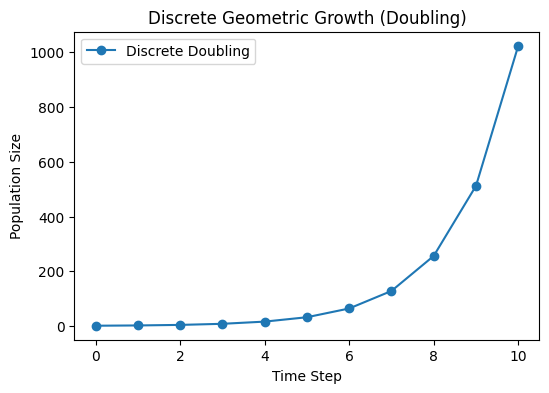

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters for the discrete model
R = 2.0        # synchronous doubling factor (per time step)
N0 = 1         # initial population (say, 1 cell)
tmax = 10      # number of discrete time steps

# Iterate
N_discrete = [N0]
for _ in range(tmax):
    N_discrete.append(R * N_discrete[-1])

# Plot
time_points = np.arange(tmax + 1)
plt.figure(figsize=(6, 4))
plt.plot(time_points, N_discrete, marker='o', label='Discrete (R=2)')
plt.xlabel('Time step')
plt.ylabel(r'Population size $N$')
plt.title('Discrete geometric growth (doubling)')
plt.legend()
plt.show()

## Continuous Growth

In continuous models, we treat population growth as happening at every instant rather than in discrete steps.

### Exponential Growth
A continuous model can be written as a differential equation:

$$
\frac{dN}{dt} = r\,N(t),
$$

where $r$ is the intrinsic (per-capita) growth rate (units: time$^{-1}$). The solution is:

$$
N(t) = N_0\,e^{r t}.
$$

**Note on notation:** many microbiology texts write the intrinsic growth rate as $\mu$ ("specific growth rate"); throughout this chapter we use $r$ for consistency, and you can treat $\mu\equiv r$ unless stated otherwise.

When interpreted at large population sizes, this model can approximate the effect of many asynchronous cell divisions happening randomly but with an average per-capita rate $r$.

### Relationship to Discrete Growth
If in the discrete model $N_{t+1} = R\,N_t$, after $T$ time steps, $N_T = R^T N_0$. Comparing with $N(t) = N_0 e^{r t}$ for the continuous case, we often identify:

$$
R = e^{r\,\Delta t},
$$

assuming each time step is $\Delta t$. So

$$
r = \frac{1}{\Delta t}\ln(R).
$$

Thus, discrete and continuous models are conceptually linked. As $\Delta t\rightarrow 0$, discrete growth steps become more closely approximated by a continuous growth process.

**Units sanity check:** $r$ has units time$^{-1}$, while $R$ is dimensionless.

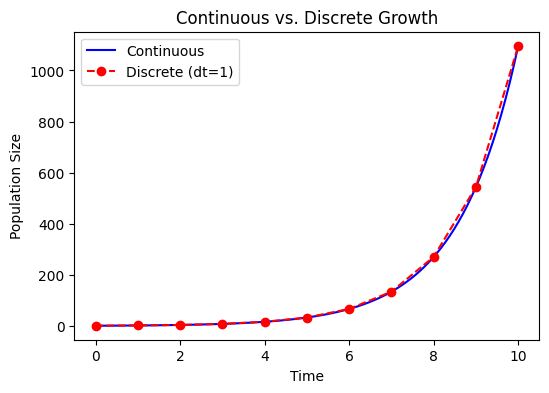

In [ ]:
# Let's compare discrete and continuous growth numerically.

r = 0.7       # intrinsic growth rate per time unit
N0_cont = 1   # initial population
t_end = 10.0  # total time

# Continuous solution: dN/dt = r N(t)
def N_continuous(t, N0, r):
    return N0 * np.exp(r * t)

# For discrete steps, pick a time step dt
dt = 1.0
R = np.exp(r * dt)  # discrete multiplicative factor per time step

num_steps = int(t_end / dt)
N_discrete_model = [N0_cont]
for _ in range(num_steps):
    N_discrete_model.append(R * N_discrete_model[-1])

# Sample the continuous solution densely for plotting
time_array = np.linspace(0, t_end, 200)
N_continuous_vals = N_continuous(time_array, N0_cont, r)

plt.figure(figsize=(6, 4))
plt.plot(time_array, N_continuous_vals, 'b-', label='Continuous')
plt.plot(np.arange(num_steps + 1), N_discrete_model, 'ro--', label=f'Discrete (dt={dt:g}, R={R:.2f})')
plt.xlabel('Time')
plt.ylabel(r'Population size $N$')
plt.title('Continuous vs discrete exponential growth')
plt.legend()
plt.show()

## Incorporating Metabolic Effects

 > Link back: the key message from [Metabolic basis](metabolic-basis) is that growth and reproduction depend on **energy flux** (metabolic rate) and the **cost** of building/maintaining biomass. In population models, we typically fold that mechanistic detail into a small number of parameters—especially the **per-capita growth rate** $r$ (also commonly written $\mu$ in microbiology).

### Temperature Dependence
Enzymatic processes in the cell generally speed up with increasing temperature (until proteins denature at high $T$). For simplicity, we can model $r$ via an Arrhenius‐type expression ({cite}`arrhenius1889inversion`; see also {cite}`eyring1935activatedcomplex`):

$$
r(T) = r_0 \exp\Bigl(-\frac{E}{k_B T}\Bigr),
$$

where,
- $E$ is an activation energy,
- $k_B$ is Boltzmann's constant (or simply a scaling constant in some biological contexts),
- $r_0$ is a pre‐exponential factor.

As empirical context for microbes, see {cite}`ratkowsky1982relationship, schaechter1958dependency, schaechter1962balanced`.

**Units sanity check:** $r(T)$ has units time$^{-1}$, so $r_0$ must also carry units time$^{-1}$ for the exponential factor to be dimensionless.

### Cell‐Size Scaling (MTE)
A common MTE-style assumption is that **whole-organism metabolic rate** scales as $B \propto M^b$ (often $b \approx 3/4$). If growth is limited by energy processing, then a *mass-specific* rate (per unit biomass) scales like $B/M \propto M^{b-1}$. This motivates a size dependence of the intrinsic (per-capita) growth rate ({cite}`west1997science, Brown2004a`):

$$
r(T,M) = r_0 M^{b-1} \exp\Bigl(-\frac{E}{k_B T}\Bigr).
$$

With $b=3/4$, this gives $r \propto M^{-1/4}$: **smaller organisms (or smaller cells) tend to have higher mass-specific growth rates**, all else equal.

### What does size-scaling *do* to the dynamics?
Two practical consequences show up immediately:

1. **Exponential phase (early growth):**

   $$N(t) = N_0 e^{r t}$$

   so larger $M$ (smaller $r$) means a *shallower* exponential curve. The **doubling time** makes this explicit:

   $$t_d = \frac{\ln 2}{r(T,M)} \;\propto\; M^{1-b}\,\exp\Bigl(\frac{E}{k_B T}\Bigr).$$

   For $b=3/4$, $t_d \propto M^{1/4}$: larger organisms generally take longer to double.

2. **Logistic phase (resource limitation):**

   $$\frac{dN}{dt} = r(T,M)\,N\Bigl(1-\frac{N}{K}\Bigr)$$

   Size can enter *both* $r$ and $K$. A simple energetic argument is: if the environment provides a roughly fixed resource/energy supply rate $S$ and each individual requires metabolic power $B \propto M^{3/4}$, then the maximum sustainable **abundance** scales like

   $$K \propto \frac{S}{B} \propto M^{-3/4}.$$

   This means bigger organisms typically have *lower* carrying capacities in terms of **number of individuals**, even if the total standing **biomass** can be similar or larger (since $K\,M \propto M^{1/4}$ under these assumptions).

   **Abundance vs biomass carrying capacity:** be explicit about what your state variable represents. In the logistic model above, $K$ is a limit on *abundance* $N$. If instead you model total biomass $B_{\text{tot}}=MN$, then the effective “carrying capacity” is a limit on biomass rather than individuals, and scaling with $M$ can look different. This is why comparing $K$ values across taxa of very different size only makes sense once you specify whether you mean **individuals**, **biomass**, or **energy flux**.

Below we’ll visualize these effects in a toy example by letting size change both $r$ and $K$.

## Logistic Growth with Temperature & Size Dependence

A standard way to extend exponential growth to include resource limitation is the **logistic model** ({cite}`verhulst1838notice`):

$$
\frac{dN}{dt} = r(T,M)\,N \Bigl(1 - \frac{N}{K}\Bigr).
$$

Here:
- $r(T,M)$ is the intrinsic per-capita growth rate (units time$^{-1}$).
- $K$ is the **carrying capacity in abundance** (i.e., the maximum sustainable *number of individuals* under the model assumptions; units: individuals).

If instead you model biomass (or energy flux) as the state variable, the corresponding “carrying capacity” would be defined in those units and can scale differently with size.

### A note on common logistic forms
You will see several algebraically related versions in the literature. The key is to check how the parameters are defined (especially units):
- **Standard (dimensionally consistent) form:** $\frac{dN}{dt}=rN\left(1-\frac{N}{K}\right)$, where $K$ has units of individuals.
- **Alternative parameterisation:** $\frac{dN}{dt}=rN\,(K-N)$ is only dimensionally correct if $K$ is interpreted as *inverse individuals* (or if $r$ has been rescaled accordingly). In ecology, authors sometimes write a form like this with parameters redefined; don’t mix parameter meanings across forms.

In the previous chapter we motivated how temperature (and, in simple allometric arguments, size) can shape the per-capita growth parameter. A common metabolically motivated form is ({cite}`west1997science, Brown2004a`; microbial temperature dependence examples in {cite}`ratkowsky1982relationship, schaechter1958dependency`):

$$
r(T,M) = r_0\, M^{b-1}\, \exp \Bigl(-\frac{E}{k_B T}\Bigr).
$$

For the commonly used case $b=3/4$, this becomes $r(T,M)=r_0\,M^{-1/4}\exp\bigl(-E/(k_B T)\bigr)$, so the logistic model can be written as:

$$
\frac{dN}{dt} = \Bigl[
  \underbrace{
    r_0\,M^{-\tfrac{1}{4}}
    \exp \Bigl(-\tfrac{E}{k_B T}\Bigr)
  }_{\text{Temperature \& size dependent rate}}
\Bigr]
 N
 \Bigl(1 - \tfrac{N}{K}\Bigr).
$$

<!-- Below, we do a simple numerical integration of this logistic equation. -->

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def r_TM(T, M, r0=1.0, E=0.65, kB=0.001987, b=0.75):
    """Toy MTE-style intrinsic growth rate r(T,M).
    
    Notes:
      - This is a deliberately simplified form to show scaling effects.
      - Units depend on how you choose r0, E, and kB; focus on *relative* differences across M and T.
    """
    return r0 * (M ** (b - 1.0)) * np.exp(-E / (kB * T))

def K_M(M, K0=1_000.0, exponent=-0.75):
    """Toy size-scaling for carrying capacity in *abundance* (number of individuals)."""
    return K0 * (M ** exponent)

def logistic_euler(N0, r, K, t_end=20.0, dt=0.01):
    times = np.arange(0.0, t_end + dt, dt)
    N = np.zeros_like(times)
    N[0] = N0
    for i in range(1, len(times)):
        Ni = N[i - 1]
        dN = r * Ni * (1.0 - Ni / K)
        N[i] = max(0.0, Ni + dN * dt)
    return times, N

# Compare different organism/cell sizes (relative masses) at the same temperature
T = 300.0
masses = np.array([1.0, 16.0, 256.0])  # relative mass units
N0 = 10.0
t_end = 25.0

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

# (1) Exponential phase: size only affects r, so curves differ in steepness
t = np.linspace(0, t_end, 300)
for M in masses:
    r = r_TM(T, M)
    N_exp = N0 * np.exp(r * t)
    axes[0].plot(t, N_exp, label=f"M={M:g}, r~{r:.3f}")
axes[0].set_title("Exponential growth: size changes the slope")
axes[0].set_xlabel("Time")
axes[0].set_ylabel(r"Population size $N$")
axes[0].set_yscale("log")
axes[0].legend()

# (2) Logistic phase: size can affect both r and K (abundance carrying capacity)
for M in masses:
    r = r_TM(T, M)
    K = K_M(M)
    times, N_log = logistic_euler(N0=N0, r=r, K=K, t_end=t_end, dt=0.01)
    axes[1].plot(times, N_log, label=f"M={M:g}, K~{K:.0f}")
axes[1].set_title("Logistic growth: size changes both rate and K")
axes[1].set_xlabel("Time")
axes[1].set_ylabel(r"Population size $N$")
axes[1].legend()

plt.show()

### Discrete Logistic Growth, Bifurcations, and Metabolic Constraints

A common **dimensionless** discrete-time model for density dependence is the *logistic map*. For a scaled population $x_t \in [0,1]$ (think $x_t = N_t/K$), it is:

$$
x_{t+1} = r_{\mathrm{map}}\,x_t\,(1-x_t).
$$

**Why use a map at all?** Discrete-time models are most natural when reproduction and/or density dependence occur in pulses (seasonal breeding, discrete generations, periodic harvesting, pulsed resources), or when you only observe the system at regular intervals. They can also be useful as *caricatures* of more complex continuous dynamics.

**When not to use it:** if births and deaths occur continuously and the time step is an arbitrary sampling choice, a continuous-time model (ODE) is often more defensible; discrete maps can exaggerate instability if the step is too large.

**Units sanity check:** $x_t$ and $r_{\mathrm{map}}$ are both dimensionless.

This equation can exhibit stable fixed points, cycles of period 2, 4, 8, … and eventually *chaos* as $r_{\mathrm{map}}$ increases (see {cite}`may1976simple`; for period-doubling universality see {cite}`feigenbaum1978universality`).

### Connection to Microbial Growth (and Metabolism)
- In real microbial systems, temperature and cell size affect the **continuous-time** intrinsic growth rate $r(T,M)$ (often written $\mu(T,M)$ in microbiology).
- When we observe populations at discrete intervals (e.g., daily sampling, or per generation), $r(T,M)$ induces an effective discrete multiplier $R=e^{r\Delta t}$ during the early (near-exponential) phase.
- After rescaling abundances to $x_t\in[0,1]$ and choosing a particular discrete-time model, changes in $T$ and $M$ can be interpreted as shifting an *effective* density-dependent parameter such as $r_{\mathrm{map}}$ (larger $r\Delta t$ typically corresponds to larger $r_{\mathrm{map}}$, though the exact mapping depends on how you discretise and rescale).

### Basic Bifurcation Diagram

A *bifurcation diagram* for the logistic map shows, for each $r_{\mathrm{map}}$, the long-term values of $x$ after discarding initial transients:
- At lower $r_{\mathrm{map}}$ (e.g., $0 < r_{\mathrm{map}} < 1$), $x=0$ is stable (extinction).
- For $1 < r_{\mathrm{map}} < 3$, the system approaches a stable fixed point.
- At $r_{\mathrm{map}}=3$, the system bifurcates to a period-2 cycle; further increases give period-4, period-8, etc.
- Around $r_{\mathrm{map}} \approx 3.5699\ldots$, the system enters chaos (with periodic windows).

Below, we implement the standard logistic map, vary $r_{\mathrm{map}}$ in $[0,4]$, iterate many steps, discard transients, and plot the remaining states.

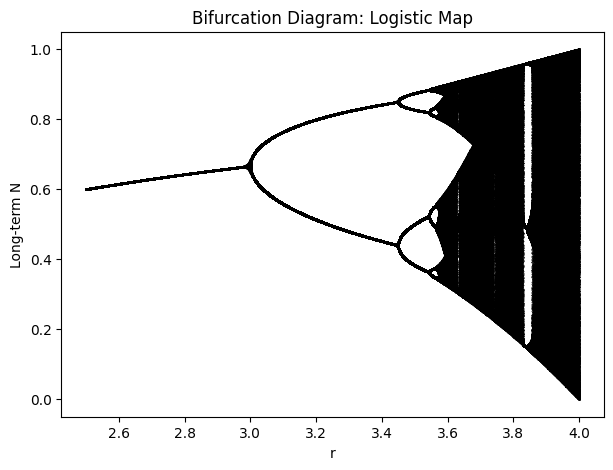

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def logistic_map(x, r_map):
    return r_map * x * (1 - x)

def bifurcation_diagram(r_min=2.5, r_max=4.0, steps=1000, discard=200, resolution=4000):
    """
    Generate (r_map, x) pairs for a bifurcation diagram of the logistic map:
        x_{t+1} = r_map * x_t * (1 - x_t).
    """
    r_values = np.linspace(r_min, r_max, resolution)
    r_list = []
    x_list = []

    for r_map in r_values:
        x = np.random.rand()  # initial condition in (0,1)
        for _ in range(discard):
            x = logistic_map(x, r_map)
        for _ in range(discard, steps):
            x = logistic_map(x, r_map)
            r_list.append(r_map)
            x_list.append(x)

    return np.array(r_list), np.array(x_list)

r_bif, x_bif = bifurcation_diagram(r_min=2.5, r_max=4.0, steps=1000, discard=200, resolution=2000)

plt.figure(figsize=(7, 5))
plt.scatter(r_bif, x_bif, s=0.1, color='black')
plt.xlabel(r'$r_{\mathrm{map}}$')
plt.ylabel(r'Long-term $x$')
plt.title('Bifurcation diagram: logistic map')
plt.show()

### Interpreting Temperature & Cell-Size Effects as Parameter Shifts

To connect continuous-time growth rates back to discrete-time dynamics, it helps to separate three related (but distinct) objects:
- $r(T,M)$: a **continuous-time** intrinsic growth rate (units time$^{-1}$)
- $R=e^{r\Delta t}$: a **discrete multiplicative factor** over an observation interval $\Delta t$ during the near-exponential phase
- $r_{\mathrm{map}}$: a **dimensionless** parameter in a chosen discrete-time density-dependent map (like the logistic map)

One simple way to discretise the continuous logistic model is an Euler step:

$$
N_{t+1} = N_t + r(T,M)\,N_t\Bigl(1 - \frac{N_t}{K}\Bigr)\,\Delta t.
$$

If we scale by $K$ and define $x_t = N_t/K$, then:

$$
x_{t+1} = x_t + r(T,M)\,\Delta t\,x_t(1-x_t).
$$

The **logistic map** is a different (but qualitatively similar) discrete-time model:

$$
x_{t+1} = r_{\mathrm{map}}\,x_t(1-x_t).
$$

Important subtlety: $r_{\mathrm{map}}$ is **dimensionless** and depends on the chosen time step and rescaling. For small $r\Delta t$, the Euler form behaves like a gentle density-dependent correction to exponential growth; increasing $T$ or decreasing $M$ typically increases $r(T,M)$ and therefore increases the effective “strength” of growth over a step, which you can think of as pushing you toward larger effective $r_{\mathrm{map}}$ in map-based models (though the exact correspondence depends on your discretisation choice).

Hence, *sweeping* $r_{\mathrm{map}}$ from ~2.5 to 4.0 in the standard logistic map can be thought of (qualitatively) as increasing the effective growth-per-step, which in real systems could arise from changes in temperature and/or organism size.

Thus, bifurcation analysis of the logistic map reveals:
- Stable equilibria at low growth parameters
- Period-doubling routes to chaos as $r_{\mathrm{map}}$ increases
- Complex behaviours including periodic windows embedded in chaos

### Making Bifurcation Points Depend on Size and Temperature
The logistic map’s bifurcation points occur at fixed values of $r_{\mathrm{map}}$ (e.g., period-doubling starts at $r_{\mathrm{map}}=3$). Metabolism and size do **not** change those numerical values; instead they change the mapping from biology ($T$, $M$) to the **effective** growth-per-step parameter $r_{\mathrm{map}}$.

A simple way to *show* this is:
1. Choose a mapping $r_{\mathrm{map}} = g(r(T,M)\,\Delta t)$ that is monotone increasing in $r\Delta t$.
2. Use Arrhenius + allometry for $r(T,M)$ ({cite}`arrhenius1889inversion, west1997science, Brown2004a`).
3. Plot $r_{\mathrm{map}}(T)$ for different $M$ values and mark where it crosses the canonical bifurcation thresholds.

Below we use the simplest monotone mapping $r_{\mathrm{map}} = \exp(r\Delta t)$ (so that $\ln r_{\mathrm{map}} = r\Delta t$). This is not the only possible mapping, but it’s easy to interpret and makes the dependence on $T$ and $M$ explicit.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Model ingredients (reuse r_TM from earlier if it exists) ---
try:
    r_TM
except NameError:
    def r_TM(T, M, r0=1.0, E=0.65, kB=0.001987, b=0.75):
        return r0 * (M ** (b - 1.0)) * np.exp(-E / (kB * T))

def r_map_from_r(r, dt_map):
    """Simple monotone mapping from continuous-time rate to logistic-map parameter."""
    return np.exp(r * dt_map)

# Canonical bifurcation thresholds for the logistic map x_{t+1} = r_map x_t (1-x_t)
r_thresholds = {
    "fixed point → period-2": 3.0,
    "period-2 → period-4": 1.0 + np.sqrt(6.0),  # ≈ 3.44949
    "period-4 → period-8": 3.544090359551922,
    "period-8 → period-16": 3.564407266094041,
    "chaos onset (accumulation)": 3.569945672,
}

# Choose an observation interval (dt_map) by calibration:
# Here: pick dt_map so that at a reference (T_ref, M_ref) we sit exactly at the first period-doubling r_map=3.
T_ref = 300.0
M_ref = 1.0
r_ref = r_TM(T_ref, M_ref)
dt_map = np.log(r_thresholds["fixed point → period-2"]) / r_ref

print(f"Calibration: at T={T_ref} K, M={M_ref}, dt_map={dt_map:.3f} gives r_map=3")

# Compute r_map(T) curves for different sizes
T_grid = np.linspace(270.0, 390.0, 600)
masses = np.array([1.0, 16.0, 256.0])

plt.figure(figsize=(9, 5))
for M in masses:
    r_vals = r_TM(T_grid, M)
    rmap_vals = r_map_from_r(r_vals, dt_map)
    plt.plot(T_grid, rmap_vals, label=f"M={M:g}")

# Add horizontal lines at bifurcation thresholds
for name, r_star in r_thresholds.items():
    plt.axhline(r_star, color='k', alpha=0.2)
    plt.text(T_grid[0] + 1.0, r_star + 0.01, name, fontsize=9, alpha=0.7)

plt.ylim(2.5, 4.05)
plt.xlabel("Temperature (K)")
plt.ylabel(r"Effective logistic-map parameter $r_{\mathrm{map}}$")
plt.title("Size + temperature shift the *conditions* at which bifurcations occur")
plt.legend(title="Relative mass")
plt.grid(True, alpha=0.2)
plt.show()

# Estimate the temperature at which each bifurcation threshold is reached for each mass
def crossing_temperature(T, y, y_star):
    """Return approximate T where y(T) crosses y_star (assumes monotone and crossing exists)."""
    diff = y - y_star
    idx = np.where(np.sign(diff[:-1]) * np.sign(diff[1:]) <= 0)[0]
    if len(idx) == 0:
        return None
    i = idx[0]
    # linear interpolation in T
    t0, t1 = T[i], T[i + 1]
    d0, d1 = diff[i], diff[i + 1]
    if d1 == d0:
        return float(t0)
    return float(t0 + (0 - d0) * (t1 - t0) / (d1 - d0))

print("\nApprox threshold temperatures (K):")
for M in masses:
    rmap_vals = r_map_from_r(r_TM(T_grid, M), dt_map)
    temps = {name: crossing_temperature(T_grid, rmap_vals, r_star) for name, r_star in r_thresholds.items()}
    temps_fmt = {k: (None if v is None else round(v, 1)) for k, v in temps.items()}
    print(f"  M={M:g}: {temps_fmt}")

## Considering External Impacts on Population Growth

So far, the logistic model treats population growth as self-limited by density:

$$
\frac{dN}{dt} = r\,N\Bigl(1 - \frac{N}{K}\Bigr),
$$

where $r$ is the intrinsic (per-capita) growth rate and $K$ is the carrying capacity (in abundance). In reality, populations are also affected by external factors such as predators, pathogens, competitors, or harvesting.

Suppose the predator population is $P$, and per-predator consumption depends on prey abundance through a functional response $f(N)$. Then predation removes $f(N)P$ prey per unit time, giving:

$$
\frac{dN}{dt} = r\,N\Bigl(1 - \frac{N}{K}\Bigr) - f(N)P.
$$

If consumed prey are converted into predator births with efficiency $e$, and predators die at per-capita rate $m$, then predator dynamics are:

$$
\frac{dP}{dt} = e f(N)P - mP.
$$

Together:

$$
\begin{aligned}
&\frac{dN}{dt} = r N \left(1 - \frac{N}{K}\right) - f(N)P,\\
&\frac{dP}{dt} = e f(N)P - mP.
\end{aligned}
$$

To simplify, take a linear functional response $f(N)=aN$ (Type I). Then:

$$
\begin{aligned}
&\frac{dN}{dt} = r N \left(1 - \frac{N}{K}\right) - aNP,\\
&\frac{dP}{dt} = eaNP - mP.
\end{aligned}
$$

If we interpret $N$ as a resource $R$ and predators as consumers $C$, and define $w = ea$, we can write a simple consumer–resource model:

$$
\begin{aligned}
&\frac{dR}{dt} = r R \left(1 - \frac{R}{K}\right) - aRC,\\
&\frac{dC}{dt} = wRC - mC.
\end{aligned}
$$

### A Simple Example

When we consider a system with one consumer and one resource:

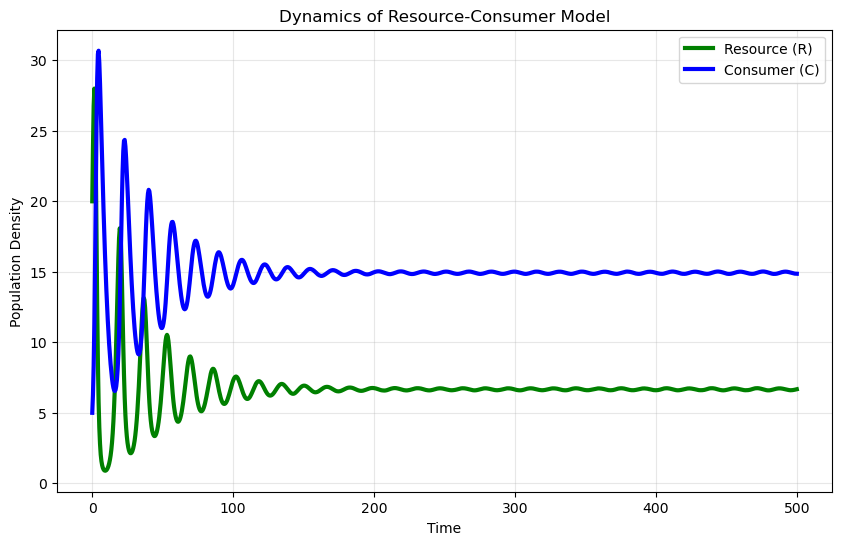

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Parameters for the consumer–resource model
r = 0.8    # intrinsic growth rate of resource (time^-1)
K = 100    # carrying capacity of resource (abundance)
a = 0.05   # consumption rate
w = 0.03   # conversion efficiency parameter (w = e*a in the linear-response case)
m = 0.2    # mortality rate of consumer (time^-1)

# Time parameters
t_start = 0
t_end = 500
t_eval = np.linspace(t_start, t_end, 1000)

# Initial conditions
initial_conditions = [20, 5]  # [Resource, Consumer]

def resource_consumer_model(t, y):
    """ODE system for a simple consumer–resource model."""
    R, C = y
    dR_dt = r * R * (1 - R / K) - a * R * C
    dC_dt = w * R * C - m * C
    return [dR_dt, dC_dt]

solution = solve_ivp(
    resource_consumer_model,
    [t_start, t_end],
    initial_conditions,
    t_eval=t_eval,
    method='RK45',
)

time = solution.t
resource = solution.y[0]
consumer = solution.y[1]

plt.figure(figsize=(10, 6))
plt.plot(time, resource, 'g-', linewidth=3, label='Resource (R)')
plt.plot(time, consumer, 'b-', linewidth=3, label='Consumer (C)')
plt.xlabel('Time')
plt.ylabel('Population density')
plt.title('Dynamics of a consumer–resource model')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Exercise template: fit a logistic curve (simple approach)
import numpy as np
import matplotlib.pyplot as plt

# This example requires scipy
from scipy.optimize import curve_fit

# TODO: replace with real saturating-growth data
t = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8], dtype=float)
N = np.array([1, 2, 4, 8, 15, 25, 40, 55, 65], dtype=float)

# Closed-form logistic solution for fitting: N(t) = K / (1 + A e^{-r t})
def logistic_solution(t, r, K, A):
    return K / (1.0 + A * np.exp(-r * t))

# Initial guesses
K0 = N.max()
r0 = 0.5
A0 = (K0 / N[0]) - 1.0
p0 = [r0, K0, A0]

params, cov = curve_fit(logistic_solution, t, N, p0=p0, bounds=(0, np.inf))

r_hat, K_hat, A_hat = params
print(f"Fitted r = {r_hat:.4f} (time^-1)")
print(f"Fitted K = {K_hat:.2f}")

# Plot fit
t_fine = np.linspace(t.min(), t.max(), 200)
N_fit = logistic_solution(t_fine, r_hat, K_hat, A_hat)

plt.figure(figsize=(6, 4))
plt.scatter(t, N, label="data")
plt.plot(t_fine, N_fit, label="logistic fit")
plt.xlabel("Time")
plt.ylabel(r"Population size $N$")
plt.title("Logistic curve fit")
plt.legend()
plt.show()

In [ ]:
# Exercise template: estimate r from (t, N) data
import numpy as np
import matplotlib.pyplot as plt

# Example data (replace with your own)
t = np.array([0, 1, 2, 3, 4, 5], dtype=float)
N = np.array([1, 2.1, 4.3, 8.6, 17.0, 33.8], dtype=float)

# Fit r by linear regression on log-scale: ln N = ln N0 + r t
logN = np.log(N)
r_hat, logN0_hat = np.polyfit(t, logN, 1)
N0_hat = np.exp(logN0_hat)
t_d = np.log(2.0) / r_hat

print(f"Estimated r = {r_hat:.4f} (time^-1)")
print(f"Estimated N0 = {N0_hat:.3f}")
print(f"Doubling time t_d = {t_d:.3f} time units")

# Visualise fit
t_fine = np.linspace(t.min(), t.max(), 200)
N_fit = N0_hat * np.exp(r_hat * t_fine)
plt.figure(figsize=(6, 4))
plt.scatter(t, N, label='data')
plt.plot(t_fine, N_fit, label='exp fit')
plt.yscale('log')
plt.xlabel('Time')
plt.ylabel(r'Population size $N$')
plt.title('Exponential fit (log scale)')
plt.legend()
plt.show()

## Structured populations
So far, we assumed individuals are identical. But populations often have **age/stage structure**, and vital rates (survival, fecundity) vary across classes.

Two classic examples:
1. Fibonacci's rabbits (a 2-stage recursion)
2. Leslie matrix (age-structured projection matrix) ({cite}`Leslie1945, Caswell2001`)

The key modelling move is to track a *vector* of abundances by class, and update it each time step with a **projection matrix**.

### Fibonacci rabbits
Fibonacci's problem can be interpreted as an effectively 2-stage system (baby $\to$ adult).
$$
F_n = F_{n-1} + F_{n-2}
$$
- $F_{n-1}$: adults last month (who survive and breed again)
- $F_{n-2}$: babies who have just matured (and can now breed)

This is a specific case of a **matrix model**: a 2-stage population vector updated by a fixed projection matrix ({cite}`Leslie1945, Caswell2001`).

In [ ]:
def simulate_fib(n):
    fib = [0, 1]
    for i in range(2, n+1):
        fib.append(fib[-1] + fib[-2])
    return fib

print("Fibonacci sequence up to month 12:")
print(simulate_fib(12))

### Leslie matrix model
Let the population vector at time $t$ be
$$
\mathbf{u}_t = (u_{1,t}, u_{2,t}, \dots, u_{\omega,t})^\top
$$
for $\omega$ age classes. A Leslie matrix $L$ maps $\mathbf{u}_{t+1} = L\mathbf{u}_t$ ({cite}`Leslie1945`; see also {cite}`Caswell2001`).

- top row: age-specific fecundities (offspring contributions)
- subdiagonal: survival probabilities to next age class

**Interpretation:** repeated multiplication by $L$ projects the population forward in discrete steps (e.g., years). The dominant eigenvalue $\lambda_1$ gives the long-run multiplicative growth factor per step, and the associated eigenvector gives the stable age distribution (after normalisation).

Long-run growth is governed by the dominant eigenvalue $\lambda_1$:
- $\lambda_1>1$: growth
- $\lambda_1<1$: decline
- stable age distribution given by dominant eigenvector

In [ ]:
def simulate_leslie(L, u0, T=20):
    u = np.array(u0, dtype=float)
    traj = [u.copy()]
    for _ in range(T):
        u = L @ u
        traj.append(u.copy())
    return np.arange(T+1), np.array(traj)

# Example 3-age Leslie model (illustrative)
L = np.array([
    [0.0, 2.0, 1.0],
    [0.5, 0.0, 0.0],
    [0.0, 0.7, 0.0],
])

u0 = [100, 50, 25]
t, traj = simulate_leslie(L, u0, T=25)

plt.figure()
for i in range(traj.shape[1]):
    plt.plot(t, traj[:, i], label=f"Age class {i+1}")
plt.xlabel("t")
plt.ylabel("Individuals")
plt.title("Leslie matrix dynamics (illustrative)")
plt.legend()
plt.show()

lam = max(np.real(np.linalg.eigvals(L)))
lam

## Metapopulations: Levins model and rescue effect

A metapopulation is a set of habitat patches that can be occupied or empty. Let $p(t)$ be the fraction of occupied patches (so $p\in[0,1]$).

### Levins model
A classic starting point is the Levins patch-occupancy model ({cite}`Levins1968`):
$$
\frac{dp}{dt} = cp(1-p) - ep
$$
- $c$: colonisation rate (time$^{-1}$)
- $e$: extinction rate (time$^{-1}$)

Equilibria:
- $p^*=0$ always
- $p^*=1-e/c$ if $c>e$

**Units sanity check:** $p$ is dimensionless, so $dp/dt$ has units time$^{-1}$; therefore $c$ and $e$ must have units time$^{-1}$.

**A useful diagnostic plot:** plot $\dot p = dp/dt$ versus $p$ and mark where it crosses zero. The sign of $\dot p$ tells you whether occupancy increases or decreases, and makes thresholds (e.g., $c=e$) visually obvious.

### Rescue effect (one simple form)
Extinction can decline as occupancy increases (e.g., through immigration rescuing local populations). One simple illustrative form is:
$$
\frac{dp}{dt} = cp(1-p) - ep(1-p) = (c-e)p(1-p).
$$
Now equilibria are 0 and 1, with a threshold at $c=e$.

In [ ]:
def levins_rhs(t, y, c, e):
    p = y[0]
    return [c*p*(1-p) - e*p]

def rescue_rhs(t, y, c, e):
    p = y[0]
    return [(c-e)*p*(1-p)]

def simulate_ode(rhs, y0, t_end=200, args=(), n=2000):
    t_eval = np.linspace(0, t_end, n)
    sol = solve_ivp(lambda t,y: rhs(t,y,*args), (0,t_end), [y0], t_eval=t_eval,
                    rtol=1e-9, atol=1e-12)
    return sol.t, sol.y[0]

# Levins
t, p = simulate_ode(levins_rhs, y0=0.01, t_end=200, args=(0.15, 0.05))
plt.figure()
plt.plot(t, p)
plt.xlabel("t")
plt.ylabel("p(t)")
plt.title("Levins metapopulation model: $\\dot p=cp(1-p)-ep$")
plt.show()

# Rescue effect
t, p2 = simulate_ode(rescue_rhs, y0=0.01, t_end=200, args=(0.15, 0.05))
plt.figure()
plt.plot(t, p2)
plt.xlabel("t")
plt.ylabel("p(t)")
plt.title("Rescue-effect model: $\\dot p=(c-e)p(1-p)$")
plt.show()

## Human population illustration

Human population growth has historically been close to exponential over substantial periods, but growth rates have changed over time due to:
- demographic transition (declining fertility)
- technology and resource constraints
- policy and socioeconomic change

A simplistic way to illustrate the difference is to compare exponential and logistic projections.

In [ ]:
# Illustrative comparison: exponential vs logistic trajectories
t = np.linspace(0, 100, 500)  # years
N0 = 2.5e9
r = 0.018  # 1.8% / year (illustrative, not current)
K = 11e9

N_exp = N0*np.exp(r*t)
N_log = K/(1 + (K/N0 - 1)*np.exp(-r*t))

plt.figure()
plt.plot(t, N_exp/1e9, label="Exponential (illustrative)")
plt.plot(t, N_log/1e9, label="Logistic (illustrative)")
plt.axhline(K/1e9, linestyle="--", label="K")
plt.xlabel("t (years)")
plt.ylabel("Population (billions)")
plt.title("Illustrative human population: exponential vs logistic")
plt.legend()
plt.show()

## Exercises

These are intended to be short modelling + coding tasks that reinforce the main ideas (discrete vs continuous time, $r$ vs $R$, density dependence, and how $T$ and $M$ enter via metabolism). The tasks marked **(Extension)** take the same ideas further.

*(Reminder: many microbiology texts write the intrinsic per-capita growth rate as $\mu$; in this chapter we use $r$ and treat $\mu\equiv r$.)*

### 1) Estimate $r$ and doubling time from data

You are given time series data $(t_i, N_i)$ during the early growth phase. Assuming exponential growth $N(t)=N_0 e^{r t}$:
- Fit $r$ by regressing $\ln N$ on $t$.
- Report the doubling time $t_d = \ln 2/r$.
- Convert the estimate to a discrete-time multiplier $R=e^{r\Delta t}$ for a chosen sampling interval $\Delta t$.

### 2) Discrete vs continuous: when does it matter?

Simulate exponential growth in two ways over the same total time:

## Summary

* Cell division is inherently discrete (integer splits), but at large population sizes overall growth can often be approximated by continuous-time models.
* Exponential growth describes unlimited resources and is governed by an intrinsic (per-capita) growth rate $r$ (often written $\mu$ in microbiology); in discrete time this corresponds to a step multiplier $R=e^{r\Delta t}$.
* Logistic growth incorporates resource limitation via a carrying capacity $K$ (typically in abundance unless otherwise stated) ({cite}`verhulst1838notice`).
* Reaction rates (and thus growth) typically increase with temperature in an Arrhenius/Eyring-like way—up to an optimum or denaturation point in real cells ({cite}`arrhenius1889inversion, eyring1935activatedcomplex, ratkowsky1982relationship, schaechter1958dependency`).
* Smaller organisms have higher mass-specific growth rates ({cite}`west1997science, Brown2004a`; $r\propto M^{b-1}$), linking metabolism and demography.
* In discrete-time density-dependent models like the logistic map, increasing the effective growth-per-step (e.g., via higher temperature) can push the system toward larger $r_{\mathrm{map}}$ and more complex dynamics ({cite}`may1976simple, feigenbaum1978universality`).
* Structured populations can be represented with stage/age classes (e.g., Fibonacci rabbits as a 2-stage recursion, and Leslie matrices in general), where long-run growth and stable structure are governed by the dominant eigenvalue and eigenvector ({cite}`Leslie1945, Caswell2001`).
* Metapopulations model occupancy across habitat patches; in the Levins framework $p(t)$ changes via colonisation and extinction, and “rescue effect” variants capture decreasing extinction risk as occupancy increases ({cite}`Levins1968`).
* Simple human-population trajectories provide a concrete illustration of how exponential and logistic assumptions yield very different forecasts, especially over long time horizons.